# 04. Customer churn and lifetime value (Module 4)

**Business question.** Which customers should relationship managers (RMs) prioritise for retention?
And if NovaFin can contact only **1,000** customers, whom should it call?

**Chain.** Customer data → churn probability (ML) and customer lifetime value (finance) → expected value at risk
(churn probability × CLV) → 2×2 segments and a ranked list of 1,000 → value protected by the campaign
(feeds the digital banking and wealth lines in notebook 10).

**Brief tasks covered.**
1. Churn prediction (`Churn_Flag`), compare models.
2. Estimate CLV from the customer financial variables.
3. Four segments (Protect / Priority retention / Maintain / Low-cost intervention) and the 1,000-customer list.

**Leakage rule agreed in notebook 00.** `Estimated_CLV` is kept **out** of the churn features: it is a derived
value score, and we want churn and value to be two independent inputs to the targeting decision.

In [1]:
import sys; sys.path.insert(0, '../src')   # make the shared helper module importable
from novafin import *                       # shared assumptions, loaders, metrics, plot style
RES, FIG = use_module('04')                 # this module's output folders (results/ and figures/)

NovaFin helpers loaded. Root: C:\Users\pravi\PG IITB\Machine Learning in Finance\capstone project solution\novafin_capstone
Outputs -> results/Module_04_Churn_CLV/ and figures/Module_04_Churn_CLV/


In [2]:
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold   # cross-validation schemes
from sklearn.model_selection import cross_validate, cross_val_predict          # CV scoring and out-of-fold predictions
from sklearn.linear_model import LogisticRegression, LinearRegression          # churn baseline; CLV formula recovery
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler                               # scaling for the logistic model
from sklearn.pipeline import make_pipeline                                     # prep + model in one object
from scipy import stats                                                        # statistical tests
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

In [3]:
cust = load('customers')                         # 5,000 customers, money columns in rupees (see notebook 00)
print(cust.shape)                                # rows, columns
cust.head()

(5000, 13)


,Customer_ID,Age,Annual_Income,Account_Balance,Products_Held,Transactions_Per_Month,Digital_Usage,Complaints,Loan_Balance,Investment_Balance,Relationship_Length_Years,Churn_Flag,Estimated_CLV
0,300001,51,515268.04,898438.26,2,12,71.29,1,392907.06,1933423.83,3,0,82080.38
1,300002,29,1991863.53,87131.43,4,16,57.60,0,84011.88,221005.37,10,0,87274.72
2,300003,55,2407704.14,886429.96,1,19,93.20,2,1326810.53,2657738.86,7,0,176662.09
3,300004,56,499119.56,188830.95,5,21,49.78,1,121135.72,526083.05,16,0,31552.83
4,300005,55,2855843.50,595025.85,1,17,100.00,2,323896.82,1649877.84,6,0,155669.08


In [4]:
print('Missing values:', int(cust.isna().sum().sum()), '| duplicate customers:', int(cust.Customer_ID.duplicated().sum()))
print('Churners:', int(cust.Churn_Flag.sum()), 'of', len(cust), '| churn rate:', round(cust.Churn_Flag.mean(), 4))

Missing values: 0 | duplicate customers: 0
Churners: 89 of 5000 | churn rate: 0.0178


**Only 89 churners.** That is a very small number of positive cases. Every metric below will be noisy, and a
single train/test split would leave only ~18 churners to test on. So we use **repeated cross-validation** for model
comparison and **out-of-fold** probabilities for scoring every customer.

## 1. Exploratory analysis: what do churners look like?

In [5]:
cust['Complaints_Grp'] = cust.Complaints.clip(upper=5).astype(str).replace('5', '5+')     # group the rare 5-8 values
cust['Digital_Q'] = pd.qcut(cust.Digital_Usage, 5, labels=['Q1 low', 'Q2', 'Q3', 'Q4', 'Q5 high'])
cust['Tenure_Grp'] = pd.cut(cust.Relationship_Length_Years, [0, 3, 7, 12, 19], labels=['1-3y', '4-7y', '8-12y', '13-19y'])
cust['Age_Grp'] = pd.cut(cust.Age, [20, 30, 40, 50, 60, 75], labels=['21-30', '31-40', '41-50', '51-60', '61-75'])
cust['Balance_Q'] = pd.qcut(cust.Account_Balance, 5, labels=['Q1 low', 'Q2', 'Q3', 'Q4', 'Q5 high'])

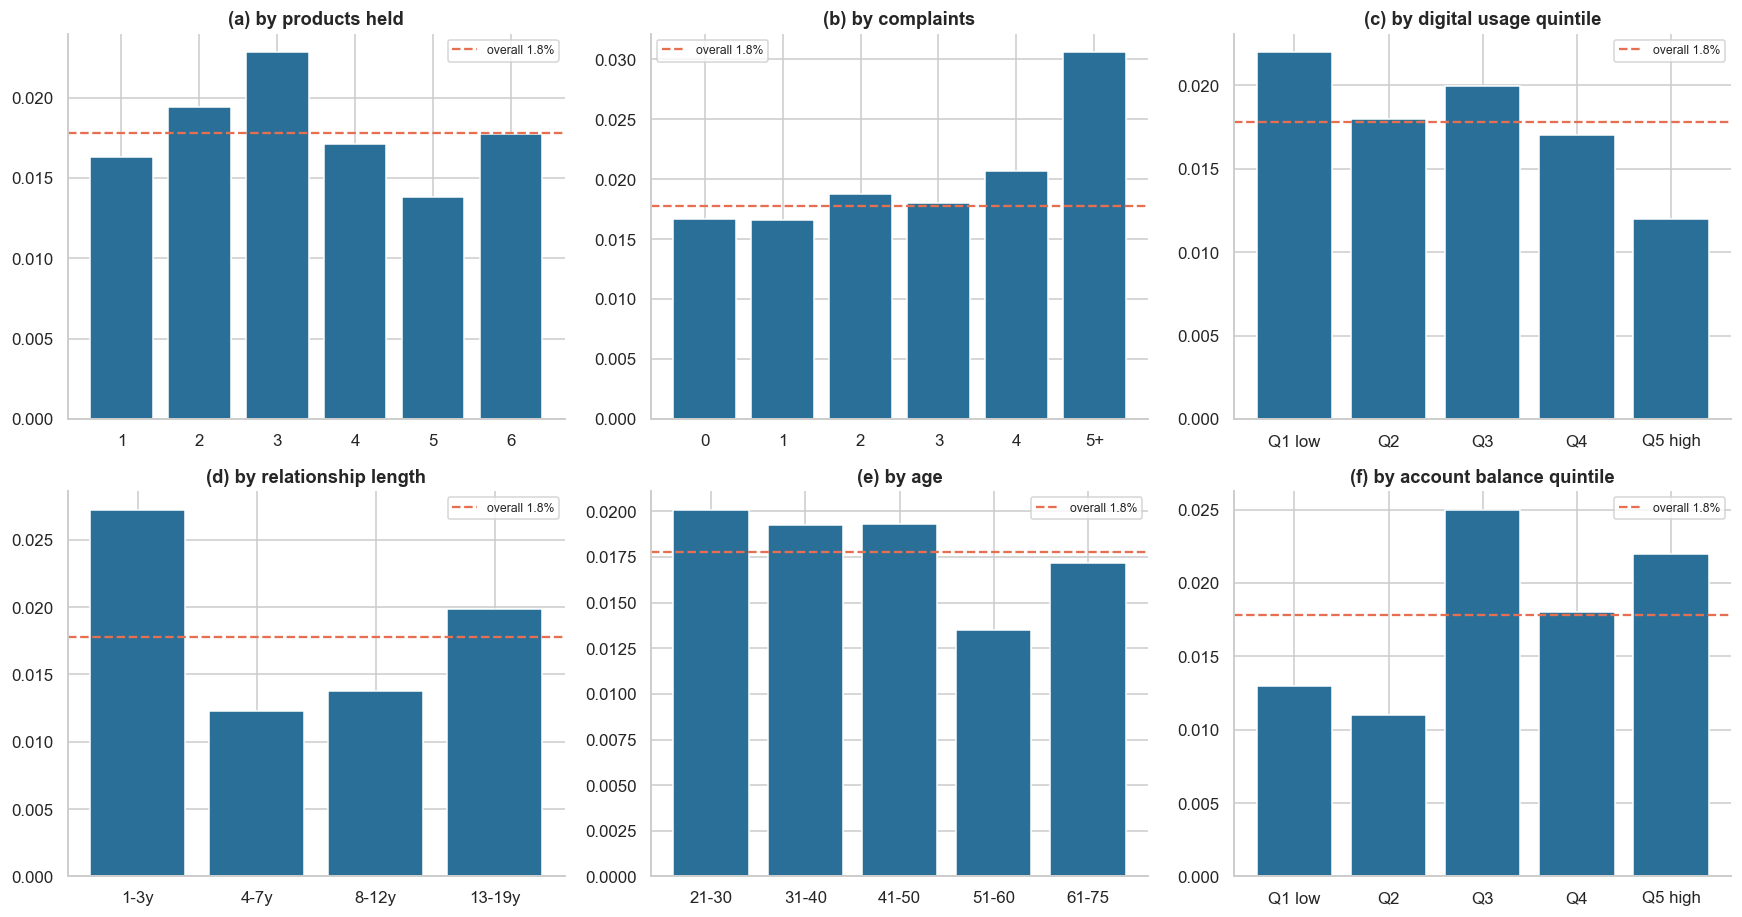

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
base = cust.Churn_Flag.mean()                                                        # overall churn rate
panels = [('Products_Held', '(a) by products held'), ('Complaints_Grp', '(b) by complaints'),
          ('Digital_Q', '(c) by digital usage quintile'), ('Tenure_Grp', '(d) by relationship length'),
          ('Age_Grp', '(e) by age'), ('Balance_Q', '(f) by account balance quintile')]
for a, (col, title) in zip(ax.ravel(), panels):
    r = cust.groupby(col, observed=True).Churn_Flag.agg(['mean', 'size'])            # churn rate and group size
    a.bar(r.index.astype(str), r['mean'], color='#2a6f97')                            # one bar per group
    a.axhline(base, ls='--', c='#e76f51', label=f'overall {base:.1%}')                # reference line
    a.set_title(title); a.legend(fontsize=8)
plt.tight_layout(); savefig('churn_eda'); plt.show()

In [7]:
def t_stat(a, b):
    """t-statistic for the difference in means of two groups: (mean_a - mean_b) / standard error.
    Rule of thumb from class: |t| > 2 means the difference is unlikely to be chance."""
    return (a.mean() - b.mean()) / np.sqrt(a.var() / len(a) + b.var() / len(b))

# Churners vs stayers: averages and the t-statistic of the difference for each customer variable
num_cols = ['Age', 'Annual_Income', 'Account_Balance', 'Products_Held', 'Transactions_Per_Month', 'Digital_Usage',
            'Complaints', 'Loan_Balance', 'Investment_Balance', 'Relationship_Length_Years']
rows = []
for c in num_cols:
    a, b = cust.loc[cust.Churn_Flag == 1, c], cust.loc[cust.Churn_Flag == 0, c]       # churners vs stayers
    rows.append({'variable': c, 'mean churners': a.mean(), 'mean stayers': b.mean(), 't-stat': t_stat(a, b)})
eda_tests = pd.DataFrame(rows).set_index('variable')
eda_tests.round(4)

,mean churners,mean stayers,t-stat
variable,,,
Age,47.5393,4.814820e+01,-0.3495
Annual_Income,987587.1798,1.059234e+06,-1.1403
Account_Balance,496683.5451,4.529885e+05,0.8309
Products_Held,3.4382,3.509100e+00,-0.3914
Transactions_Per_Month,19.0225,1.898370e+01,0.0838
Digital_Usage,60.9328,6.453310e+01,-1.6021
Complaints,1.6292,1.524100e+00,0.7614
Loan_Balance,491602.5933,4.558717e+05,0.6272
Investment_Balance,594424.4570,6.572376e+05,-0.7928


**Reading the EDA.** The bars move around the 1.8% average with no clear pattern, and **no variable differs
clearly** between churners and stayers (every |t-stat| is below 2). Very low digital usage and 5+ complaints show
slightly higher churn, but on tiny groups. This is the first warning that churn may be **hard or impossible to
predict** from these variables.

## 2. Churn models (Task 1)
**Features.** All customer variables except `Customer_ID` (identifier), `Churn_Flag` (target) and `Estimated_CLV`
(kept out by design). Three engineered ratios are added: total assets with the bank, assets ÷ income and
loans ÷ income.

In [8]:
cust['Total_Assets'] = cust.Account_Balance + cust.Investment_Balance       # money the customer keeps with NovaFin
cust['Assets_to_Income'] = cust.Total_Assets / cust.Annual_Income            # share of wealth held here
cust['Loan_to_Income'] = cust.Loan_Balance / cust.Annual_Income              # indebtedness to NovaFin
FEATURES = num_cols + ['Total_Assets', 'Assets_to_Income', 'Loan_to_Income']
X, y = cust[FEATURES], cust.Churn_Flag
print(len(FEATURES), 'features | churners', int(y.sum()))

13 features | churners 89


In [9]:
models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', C=0.1, max_iter=3000)),
    'Random forest': RandomForestClassifier(n_estimators=400, min_samples_leaf=20, class_weight='balanced_subsample',
                                            n_jobs=-1, random_state=SEED),
    'Gradient boosting': HistGradientBoostingClassifier(max_depth=2, learning_rate=0.03, max_iter=200,
                                                        class_weight='balanced', random_state=SEED),
}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)      # 25 fits per model, 18 churners per test fold

In [10]:
cv_rows = {}
for name, m in models.items():
    s = cross_validate(m, X, y, cv=rcv, scoring={'auc': 'roc_auc', 'ap': 'average_precision'}, n_jobs=-1)
    cv_rows[name] = {'ROC-AUC mean': s['test_auc'].mean(), 'ROC-AUC std': s['test_auc'].std(),
                     'PR-AUC mean': s['test_ap'].mean()}
cvres = pd.DataFrame(cv_rows).T
print('No-skill reference: ROC-AUC 0.5, PR-AUC', round(y.mean(), 4))
cvres.round(4)

No-skill reference: ROC-AUC 0.5, PR-AUC 0.0178


,ROC-AUC mean,ROC-AUC std,PR-AUC mean
Logistic regression,0.4939,0.0559,0.0303
Random forest,0.4882,0.0507,0.0220
Gradient boosting,0.5102,0.0554,0.0296


In [11]:
# Comparison table with a no-skill row: is any model worth choosing over another?
table = cvres.copy()
table.loc['No-skill (base rate)'] = [0.5, 0.0, y.mean()]                     # what a coin flip achieves
compare_models(table, 'ROC-AUC mean', chosen=None, baseline='No-skill (base rate)',
               extra=['ROC-AUC std', 'PR-AUC mean']).round(4)

,Rank,ROC-AUC mean,ROC-AUC std,PR-AUC mean,Gain vs baseline,Gap to best,Chosen
Gradient boosting,1,0.5102,0.0554,0.0296,0.0102,0.0000,
No-skill (base rate),2,0.5000,0.0000,0.0178,0.0000,0.0102,
Logistic regression,3,0.4939,0.0559,0.0303,-0.0061,0.0163,
Random forest,4,0.4882,0.0507,0.0220,-0.0118,0.0220,


**Benefit of choosing a model here: none.** Every gain vs no-skill (±0.01 AUC) is far smaller than the fold-to-fold
spread (std ≈ 0.05). Choosing gradient boosting over logistic regression buys nothing measurable.

### Is there any signal at all? Gain over no-skill vs fold-to-fold noise
If a model had real skill, its average AUC gain over 0.5 would be **large compared with the spread across folds**
(signal-to-noise > 2). Below 1, the "gain" is indistinguishable from luck.

In [12]:
signal = cvres.assign(**{'gain over 0.5': cvres['ROC-AUC mean'] - 0.5,
                         'signal-to-noise': (cvres['ROC-AUC mean'] - 0.5) / cvres['ROC-AUC std']})
signal.round(3)

,ROC-AUC mean,ROC-AUC std,PR-AUC mean,gain over 0.5,signal-to-noise
Logistic regression,0.494,0.056,0.030,-0.006,-0.110
Random forest,0.488,0.051,0.022,-0.012,-0.234
Gradient boosting,0.510,0.055,0.030,0.010,0.183


In [13]:
# Out-of-fold churn probability for every customer, from the best CV model (simplest wins ties within 0.005)
order = ['Logistic regression', 'Random forest', 'Gradient boosting']
best = cvres['ROC-AUC mean'].idxmax()
chosen = next(n for n in order if cvres.loc[best, 'ROC-AUC mean'] - cvres.loc[n, 'ROC-AUC mean'] <= 0.005)
raw = cross_val_predict(models[chosen], X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                        method='predict_proba', n_jobs=-1)[:, 1]                 # each customer scored by a model that never saw them
cust['Churn_Score'] = raw                                                         # ranking score (inflated by class weights)
cust['P_Churn'] = raw * base / raw.mean()                                         # rescaled so the average equals the 1.8% churn rate
print('chosen:', chosen)
print(binary_report(y, cust.P_Churn, chosen)[['ROC-AUC', 'PR-AUC', 'KS', 'Mean predicted', 'Actual rate']].round(4))

chosen: Gradient boosting
ROC-AUC           0.4729
PR-AUC            0.0177
KS                0.0361
Mean predicted    0.0178
Actual rate       0.0178
Name: Gradient boosting, dtype: float64


In [14]:
# Top-decile lift: do the 10% highest-scored customers churn more than average?
dec = pd.qcut(cust.Churn_Score.rank(method='first'), 10, labels=range(1, 11))   # decile 10 = highest predicted risk
lift = cust.groupby(dec, observed=True).Churn_Flag.agg(['size', 'sum', 'mean'])
lift['lift'] = lift['mean'] / base                                               # 1.0 = no better than random
lift.round(3)

,size,sum,mean,lift
Churn_Score,,,,
1,500,9,0.018,1.011
2,500,9,0.018,1.011
3,500,13,0.026,1.461
4,500,9,0.018,1.011
5,500,9,0.018,1.011
6,500,9,0.018,1.011
7,500,7,0.014,0.787
8,500,7,0.014,0.787
9,500,7,0.014,0.787


**Conclusion on churn prediction.** All three models score close to an AUC of 0.5, their gain over no-skill is far
smaller than the fold-to-fold noise (signal-to-noise well below 2), and the top decile does not concentrate churners.
**In this dataset, churn is not predictable from the customer variables provided.** (In synthetic data this usually
means the churn flag was generated at random.)

This is an important, honest finding for the Board: *a churn model would give RMs a false sense of precision.*
The targeting decision must therefore lean on **customer value**, which we can measure reliably, and treat every
customer's churn risk as close to the 1.8% average. We still keep the model's (weak) score in the ranking so the
method is ready when better behavioural data (e.g. falling balances, login trends) become available.

## 3. Customer lifetime value (Task 2)
### 3a. What is the supplied `Estimated_CLV`?
We regress it on the customer financial variables. If it is a simple formula, the regression will fit exactly.

In [15]:
pos = cust[cust.Estimated_CLV > 0]                                                  # 17 customers have CLV floored at 0
clv_vars = ['Annual_Income', 'Account_Balance', 'Loan_Balance', 'Investment_Balance', 'Complaints']
reg = LinearRegression().fit(pos[clv_vars], pos.Estimated_CLV)                     # recover the formula
print('R² =', round(reg.score(pos[clv_vars], pos.Estimated_CLV), 6), '| intercept =', round(reg.intercept_, 2))
pd.Series(reg.coef_, index=clv_vars, name='coefficient').round(4)

R² = 1.0 | intercept = -0.0


Annual_Income            0.040
Account_Balance          0.030
Loan_Balance             0.012
Investment_Balance       0.018
Complaints           -5000.000
Name: coefficient, dtype: float64

**The supplied CLV is an exact formula** (R² = 1):

$$\text{Estimated\_CLV} = \max\big(0,\; 4\%\cdot\text{Income} + 3\%\cdot\text{Account balance} + 1.2\%\cdot\text{Loans} + 1.8\%\cdot\text{Investments} - ₹5{,}000\cdot\text{Complaints}\big)$$

Read as finance, each term is an **annual profit margin**:
- 3% on deposits (net interest margin on current/savings balances),
- 1.2% on loans (lending spread after funding),
- 1.8% on investments (wealth / asset-management fee),
- 4% of income (cards, fees, cross-sell),
- minus ₹5,000 servicing cost per complaint.

So `Estimated_CLV` is really **one year of profit contribution**, not a lifetime value: it ignores how long the
customer stays and the time value of money.

### 3b. Rebuilt lifetime CLV (our transparent version)
$$CLV_i = m_i \times \sum_{t=1}^{H} \frac{(1-c_i)^{t-1}}{(1+d)^t}$$
- $m_i$ = annual margin (the supplied formula),
- $c_i$ = annual churn probability of customer *i* (`P_Churn`; we assume the churn flag measures one year),
- $d$ = 12% discount rate (shared assumption), $H$ = 10-year horizon (a prudent cap; perpetuity would overstate).

In [16]:
D, H = ASSUMPTIONS['DISCOUNT_RATE'], 10                          # discount rate and horizon in years
cust['Annual_Margin'] = cust.Estimated_CLV                       # one-year margin, as shown above

def lifetime_multiplier(c, d=D, h=H):
    """Present value of ₹1 of margin per year, while the customer stays (survival (1-c)^(t-1))."""
    t = np.arange(1, h + 1)                                       # years 1..H
    return ((1 - np.asarray(c)[:, None]) ** (t - 1) / (1 + d) ** t).sum(axis=1)

cust['CLV_Lifetime'] = cust.Annual_Margin * lifetime_multiplier(cust.P_Churn)   # rebuilt lifetime CLV in rupees
print('Average multiplier:', round(lifetime_multiplier(cust.P_Churn).mean(), 2), 'x annual margin')
print('Rank correlation, supplied vs lifetime CLV:', round(stats.spearmanr(cust.Estimated_CLV, cust.CLV_Lifetime)[0], 4))
cust[['Annual_Margin', 'CLV_Lifetime']].describe().round(0)

Average multiplier: 5.31 x annual margin
Rank correlation, supplied vs lifetime CLV: 0.9992


,Annual_Margin,CLV_Lifetime
count,5000.0,5000.0
mean,65602.0,348891.0
std,46242.0,249417.0
min,0.0,0.0
25%,34591.0,182861.0
50%,54205.0,284752.0
75%,83622.0,442967.0
max,439367.0,2314788.0


In [17]:
# Where does the customer value come from? Total annual margin split by product.
parts = pd.Series({'Income-linked fees (4%)': 0.04 * cust.Annual_Income.sum(),
                   'Deposits (3%)': 0.03 * cust.Account_Balance.sum(),
                   'Loans (1.2%)': 0.012 * cust.Loan_Balance.sum(),
                   'Investments / wealth (1.8%)': 0.018 * cust.Investment_Balance.sum(),
                   'Complaint cost (-₹5,000 each)': -5000 * cust.Complaints.sum()})
(parts / CRORE).round(2).to_frame('annual margin, ₹ crore')

,"annual margin, ₹ crore"
Income-linked fees (4%),21.16
Deposits (3%),6.81
Loans (1.2%),2.74
Investments / wealth (1.8%),5.91
"Complaint cost (-₹5,000 each)",-3.82


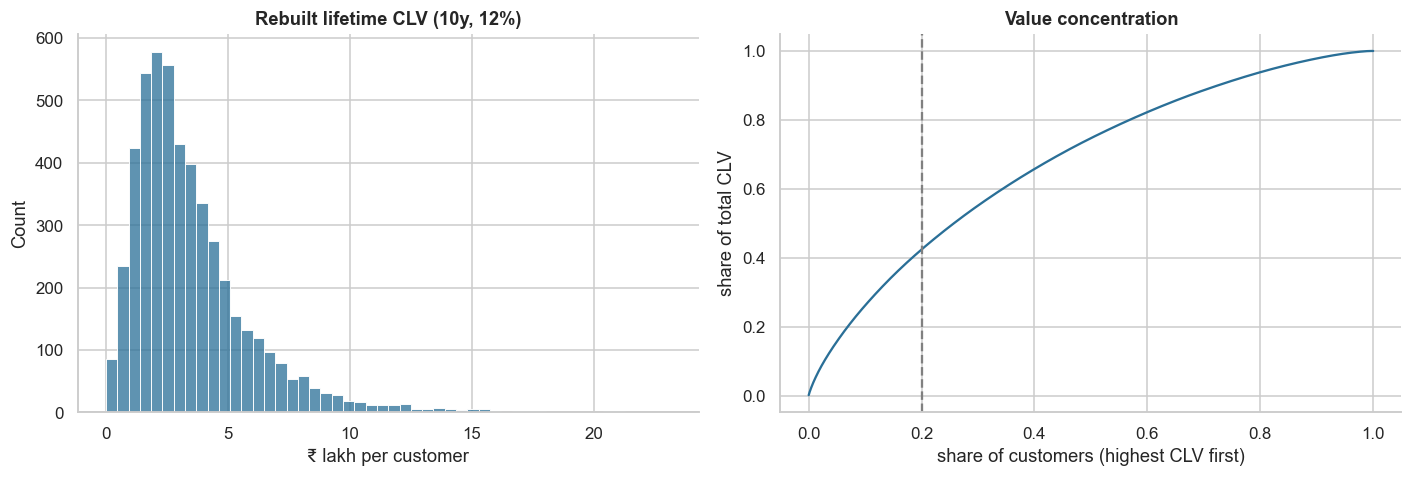

Top 20% of customers hold 0.424 of total lifetime value


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(cust.CLV_Lifetime / 1e5, bins=50, ax=ax[0], color='#2a6f97')               # in ₹ lakh
ax[0].set(title='Rebuilt lifetime CLV (10y, 12%)', xlabel='₹ lakh per customer')
srt = np.sort(cust.CLV_Lifetime.values)[::-1]                                            # customers by value, high to low
ax[1].plot(np.arange(1, len(srt) + 1) / len(srt), srt.cumsum() / srt.sum(), c='#2a6f97')  # concentration curve
ax[1].axvline(0.2, ls='--', c='grey'); ax[1].set(title='Value concentration', xlabel='share of customers (highest CLV first)', ylabel='share of total CLV')
plt.tight_layout(); savefig('churn_clv'); plt.show()
print('Top 20% of customers hold', round(srt[: len(srt) // 5].sum() / srt.sum(), 3), 'of total lifetime value')

## 4. Segments and the 1,000-customer list (Task 3)
**2×2 grid.**
- *High CLV* = above the median lifetime CLV.
- *High churn* = top 20% of the churn score. (The score is weak, so this split is labelled as indicative.)

|              | Low churn | High churn |
|---|---|---|
| **High CLV** | Protect | Priority retention |
| **Low CLV**  | Maintain | Low-cost intervention |

In [19]:
hi_clv = cust.CLV_Lifetime > cust.CLV_Lifetime.median()                       # top half by value
hi_churn = cust.Churn_Score >= cust.Churn_Score.quantile(0.80)               # top 20% by churn score
cust['Segment'] = np.select([hi_clv & ~hi_churn, hi_clv & hi_churn, ~hi_clv & ~hi_churn],
                            ['Protect', 'Priority retention', 'Maintain'], default='Low-cost intervention')
seg = cust.groupby('Segment').agg(Customers=('Customer_ID', 'size'), Realised_churn=('Churn_Flag', 'mean'),
                                  Avg_CLV_lakh=('CLV_Lifetime', lambda s: s.mean() / 1e5),
                                  Total_CLV_cr=('CLV_Lifetime', lambda s: s.sum() / CRORE))
seg.loc[['Priority retention', 'Protect', 'Low-cost intervention', 'Maintain']].round(3)

,Customers,Realised_churn,Avg_CLV_lakh,Total_CLV_cr
Segment,,,,
Priority retention,461,0.020,4.161,19.183
Protect,2039,0.019,5.450,111.124
Low-cost intervention,539,0.015,2.074,11.178
Maintain,1961,0.017,1.681,32.960


**Expected value at risk (EVaR)** is the money we expect to lose if we do nothing:
$$EVaR_i = P(\text{churn})_i \times CLV_i$$
Ranking by EVaR combines both dimensions. We compare four ways of choosing the 1,000 customers and **backtest** them
on the actual churn outcomes: how many real churners, and how much of their lifetime value, each list would have reached.

In [20]:
cust['EVaR'] = cust.P_Churn * cust.CLV_Lifetime                       # expected value at risk per customer
K = ASSUMPTIONS['RETENTION_BUDGET']                                  # 1,000 contacts (brief)
rng = np.random.default_rng(SEED)                                    # for the random benchmark
strategies = {'EVaR (churn x CLV)': cust.EVaR, 'CLV only': cust.CLV_Lifetime,
              'Churn score only': cust.Churn_Score, 'Random 1,000': pd.Series(rng.random(len(cust)), index=cust.index)}
churn_value = (cust.Churn_Flag * cust.CLV_Lifetime).sum()           # lifetime value of all customers who actually churned
bt = {}
for name, score in strategies.items():
    top = cust.loc[score.nlargest(K).index]                          # the 1,000 customers this strategy would call
    bt[name] = {'churners reached': int(top.Churn_Flag.sum()),
                'share of churners': top.Churn_Flag.sum() / cust.Churn_Flag.sum(),
                'value of churners reached (₹ cr)': (top.Churn_Flag * top.CLV_Lifetime).sum() / CRORE,
                'share of churned value': (top.Churn_Flag * top.CLV_Lifetime).sum() / churn_value,
                'total CLV of list (₹ cr)': top.CLV_Lifetime.sum() / CRORE}
pd.DataFrame(bt).T.round(3)

,churners reached,share of churners,value of churners reached (₹ cr),share of churned value,total CLV of list (₹ cr)
EVaR (churn x CLV),17.0,0.191,0.949,0.319,62.207
CLV only,14.0,0.157,1.005,0.337,73.941
Churn score only,17.0,0.191,0.477,0.160,30.361
"Random 1,000",13.0,0.146,0.313,0.105,35.005


In [21]:
# Same backtest as a comparison table: benefit of each targeting rule vs a random list
bt_tbl = pd.DataFrame(bt).T
compare_models(bt_tbl, 'value of churners reached (₹ cr)', chosen='EVaR (churn x CLV)', baseline='Random 1,000',
               extra=['churners reached', 'share of churned value', 'total CLV of list (₹ cr)']).round(3)

,Rank,value of churners reached (₹ cr),churners reached,share of churned value,total CLV of list (₹ cr),Gain vs baseline,Gap to best,Chosen
CLV only,1,1.005,14.0,0.337,73.941,0.692,0.000,
EVaR (churn x CLV),2,0.949,17.0,0.319,62.207,0.636,0.056,✔
Churn score only,3,0.477,17.0,0.160,30.361,0.164,0.528,
"Random 1,000",4,0.313,13.0,0.105,35.005,0.000,0.692,


**Reading the backtest.** All lists reach a similar *number* of churners (13–17 of 89), so the churn score adds
little. But value-led lists (EVaR or CLV only) reach churners worth **about 3× more** (≈ ₹1 crore of lifetime value
vs ₹0.31 crore for a random list), because churn hits every value tier equally. So **value-led targeting protects the
most money**. EVaR and CLV-only give almost the same result; EVaR is kept because it will automatically use better
churn data when it exists.

## 5. Campaign economics: is calling 1,000 customers worth it?
Assumptions (stated, then stress-tested):
- **Save rate** 30%: of the customers who would have churned, an RM call keeps 30%.
- **Cost per contact** ₹1,500: RM time plus a retention offer.
- Value protected = save rate × Σ EVaR of the 1,000 contacted.

In [22]:
SAVE_RATE, CONTACT_COST = 0.30, 1_500                                        # assumptions
top1000 = cust.loc[cust.EVaR.nlargest(K).index].copy()                      # the recommended list
value_protected = SAVE_RATE * top1000.EVaR.sum()                             # expected rupees kept
campaign_cost = K * CONTACT_COST                                              # rupees spent
print(f'Expected value protected: ₹{value_protected / 1e5:,.1f} lakh')
print(f'Campaign cost:            ₹{campaign_cost / 1e5:,.1f} lakh')
print(f'Net value:                ₹{(value_protected - campaign_cost) / 1e5:,.1f} lakh | ROI {value_protected / campaign_cost - 1:.0%}')

Expected value protected: ₹37.8 lakh
Campaign cost:            ₹15.0 lakh
Net value:                ₹22.8 lakh | ROI 152%


In [23]:
# Sensitivity: net value (₹ lakh) for different save rates and contact costs
grid = pd.DataFrame({f'cost ₹{c:,}': {f'save {s:.0%}': (s * top1000.EVaR.sum() - K * c) / 1e5
                                       for s in [0.1, 0.2, 0.3, 0.5]} for c in [500, 1_500, 3_000]})
grid.round(1)

,cost ₹500,"cost ₹1,500","cost ₹3,000"
save 10%,7.6,-2.4,-17.4
save 20%,20.2,10.2,-4.8
save 30%,32.8,22.8,7.8
save 50%,57.9,47.9,32.9


In [24]:
# How many customers are worth calling at all? Call only if save rate x EVaR > contact cost.
worth = cust[SAVE_RATE * cust.EVaR > CONTACT_COST]
print('Customers whose expected saving exceeds the contact cost:', len(worth))

Customers whose expected saving exceeds the contact cost: 2499


**Reading the economics.** With a 1.8% churn rate, the expected loss from any one customer is small (about 1.8% of
their lifetime value). Even so, about 2,500 customers are valuable enough that an RM call (₹1,500, 30% save rate) pays
back, more than the 1,000 the team can contact. So **RM capacity is the binding constraint**: all 1,000 contacts
should be RM calls to the top of the EVaR list, and the next ~1,500 customers should get cheap digital nudges
(app messages, email). The campaign stops paying if the save rate falls to about 10% at ₹1,500 per call.

## 6. Output: the 1,000-customer list and hand-off to notebook 10

In [25]:
top1000['Rank'] = np.arange(1, K + 1)                                                      # 1 = highest value at risk
top1000['Action'] = np.where(SAVE_RATE * top1000.EVaR > CONTACT_COST, 'RM call', 'Digital nudge')
cols = ['Rank', 'Customer_ID', 'Segment', 'P_Churn', 'Annual_Margin', 'CLV_Lifetime', 'EVaR', 'Action',
        'Products_Held', 'Digital_Usage', 'Complaints', 'Churn_Flag']
top1000[cols].to_csv(RES / 'churn_top1000.csv', index=False)                            # list for the RM team
print('saved results/churn_top1000.csv |', top1000.Action.value_counts().to_dict())
top1000[cols].head(10).round(4)

saved results/churn_top1000.csv | {'RM call': 1000}


,Rank,Customer_ID,Segment,P_Churn,Annual_Margin,CLV_Lifetime,EVaR,Action,Products_Held,Digital_Usage,Complaints,Churn_Flag
293,1,300294,Protect,0.0197,439366.88,2.314788e+06,45703.4253,RM call,3,57.95,5,0
3834,2,303835,Protect,0.0199,399209.67,2.101900e+06,41877.5370,RM call,6,72.25,3,0
4524,3,304525,Protect,0.0227,307597.68,1.604065e+06,36368.4165,RM call,3,44.31,0,0
2579,4,302580,Protect,0.0231,278418.21,1.449592e+06,33527.1903,RM call,4,63.49,1,0
4308,5,304309,Protect,0.0219,292283.58,1.528308e+06,33473.6335,RM call,3,41.71,2,0
309,6,300310,Protect,0.0201,298396.13,1.569964e+06,31604.1116,RM call,3,59.64,1,0
4706,7,304707,Protect,0.0212,283799.74,1.487466e+06,31570.7399,RM call,3,48.03,1,0
136,8,300137,Protect,0.0173,343226.85,1.823858e+06,31547.9933,RM call,3,79.45,0,0
2896,9,302897,Protect,0.0200,283666.76,1.493205e+06,29848.2531,RM call,6,73.86,0,0
3900,10,303901,Protect,0.0218,259934.11,1.359410e+06,29701.9205,RM call,2,67.58,2,0


In [26]:
book = {'customers': len(cust), 'annual_margin_cr': cust.Annual_Margin.sum() / CRORE,
        'lifetime_clv_cr': cust.CLV_Lifetime.sum() / CRORE,
        'deposits_cr': cust.Account_Balance.sum() / CRORE, 'investments_cr': cust.Investment_Balance.sum() / CRORE,
        'loans_cr': cust.Loan_Balance.sum() / CRORE}
res = {'module': 'churn',
       'assumptions': {'discount_rate': D, 'horizon_years': H, 'save_rate': SAVE_RATE, 'contact_cost_inr': CONTACT_COST,
                       'churn_flag_period': 'assumed annual'},
       'model': {'chosen': chosen, 'cv': cvres.round(4).to_dict(orient='index'),
                 'signal_to_noise': signal['signal-to-noise'].round(3).to_dict(),
                 'verdict': 'churn not predictable from supplied variables'},
       'clv_formula': {'income': 0.04, 'deposits': 0.03, 'loans': 0.012, 'investments': 0.018, 'per_complaint_inr': -5000},
       'margin_rates': {'Digital banking (deposits)': 0.03, 'Wealth management (investments)': 0.018, 'Retail lending (loans)': 0.012},
       'book': book, 'segments': seg.round(4).to_dict(orient='index'),
       'targeting_backtest': pd.DataFrame(bt).T.round(4).to_dict(orient='index'),
       'campaign': {'value_protected_inr': value_protected, 'cost_inr': campaign_cost,
                    'net_inr': value_protected - campaign_cost, 'rm_calls': int((top1000.Action == 'RM call').sum())}}
save_result('churn', res)

saved results/Module_04_Churn_CLV/churn.json


## Headline results
- **Churn is not predictable from the supplied variables.** 89 churners (1.8%). All three models score CV ROC-AUC
  ≈ 0.49–0.51 (no-skill 0.5), PR-AUC ≈ 0.02–0.03 (no-skill 0.018). Their gain over no-skill is smaller than the fold-to-fold
  noise (signal-to-noise below 1). The top-decile lift is 1.1, i.e. no concentration of churners.
  Honest message to the Board: a churn model on these data would give false precision.
- **CLV.** The supplied `Estimated_CLV` is an exact formula (R² = 1): 4% of income + 3% of deposits + 1.2% of loans
  + 1.8% of investments − ₹5,000 per complaint, i.e. a **one-year margin**. Our lifetime CLV (10 years, 12%, survival
  with churn probability) is 5.3× the annual margin: mean ₹3.5 lakh per customer, ₹174 crore for the 5,000 customers.
  Value is concentrated: the top 20% of customers hold 42% of lifetime value.
- **Where the margin comes from (₹ crore a year):** fees linked to income 21.2, deposits 6.8, investments 5.9,
  loans 2.7, complaints −3.8. Complaints cost as much as half the wealth fees, so service quality is worth money.
- **Segments.** Protect 2,039 (₹111 cr of CLV), Priority retention 461 (₹19 cr), Maintain 1,961 (₹33 cr),
  Low-cost intervention 539 (₹11 cr). Realised churn is ~1.5–2.0% in every segment, as the model predicts nothing.
- **The 1,000 list** (ranked by churn probability × lifetime CLV, saved in `results/churn_top1000.csv`): in the backtest
  it reaches 17 of 89 churners worth ₹0.95 crore of lifetime value, 3× a random list (₹0.31 crore).
- **Campaign economics** (30% save rate, ₹1,500 per call): value protected ₹37.8 lakh, cost ₹15 lakh, net
  **₹22.8 lakh (ROI 152%)**. About 2,500 customers would justify a call, so RM capacity, not budget, is the limit.
  It turns negative only if the save rate drops to about 10%.
- **For notebook 10.** Churn is a small, cheap problem (1.8% a year), so retention needs operating spend, not capital.
  The value of the customer franchise lies in **deposits (3% margin) and wealth (1.8% fee on investments)**, which
  supports the digital banking and wealth management lines.

## Risks and limitations
- Churn is unpredictable here, so P(churn) is close to the average for everyone. Real deployments need behavioural
  time-series data (balance trends, logins, product closures), which this file does not have.
- 89 churners only: every churn metric has wide uncertainty.
- The churn flag is assumed to measure one year; if it covers a shorter period, lifetime CLV falls.
- The save rate and contact cost are assumptions; the sensitivity grid shows when the campaign stops paying.
- The supplied CLV is a one-year margin formula; our lifetime CLV adds retention and discounting but no growth.